In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Menentukan lokasi root Google Drive yang telah di-mount
drive_path = '/content/drive/MyDrive'

# Menampilkan daftar berkas dan folder
try:
    files = os.listdir(drive_path)
    print(f"Daftar berkas/folder di {drive_path}:")
    for file in files:
        print(f"- {file}")
except FileNotFoundError:
    print("Drive belum terhubung atau path salah. Pastikan Drive sudah di-mount dengan benar.")

Daftar berkas/folder di /content/drive/MyDrive:
- Colab Notebooks
- Analisis Regresi Linear Berganda


In [ ]:
import pandas as pd

# Memverifikasi instalasi pandas dengan menampilkan versi aktif
print(f"Pandas berhasil diimpor! Versi yang terpasang: {pd.__version__}")

Pandas berhasil diimpor! Versi yang terpasang: 2.2.3


In [ ]:
# Installation (jalankan sekali jika paket belum tersedia)
%pip install matplotlib numpy pandas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

print("Matplotlib:", matplotlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Matplotlib: 3.10.0
NumPy: 2.4.6
Pandas: 2.2.3


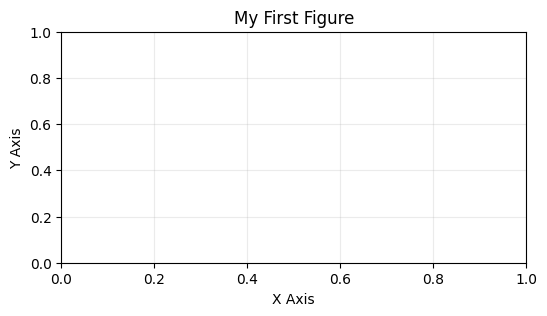

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_title("My First Figure")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
ax.grid(alpha=0.25)
plt.show()

ValueError: x and y must have same first dimension, but have shapes (5,) and (9,)

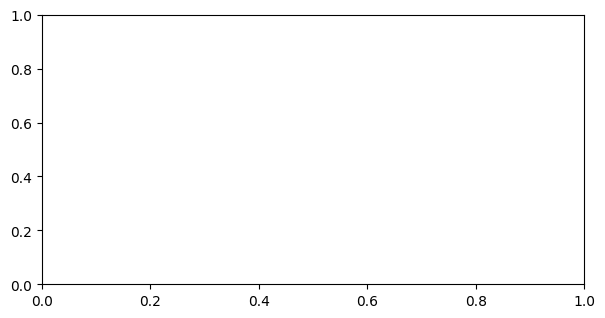

In [ ]:
weeks = np.array([1, 2, 3, 4, 5])
average_scores = np.array([60, 62.5, 65.5, 67.5, 70, 72.5, 75, 77.5, 80])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, average_scores)
ax.set_title("Average Scores by Week")
ax.set_xlabel("Week")
ax.set_ylabel("Average Score")
ax.set_xticks(weeks)
plt.show()

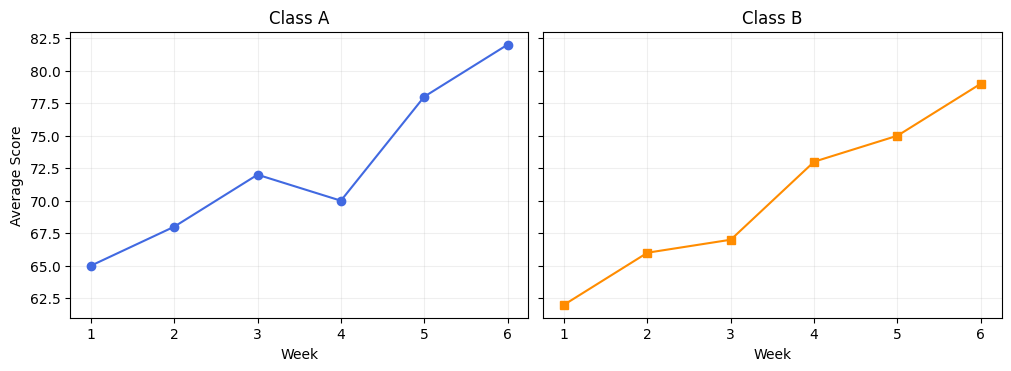

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout="constrained")
axes[0].plot(weeks, class_a, marker="o", color="royalblue")
axes[0].set(title="Class A", xlabel="Week", ylabel="Average Score")

axes[1].plot(weeks, class_b, marker="s", color="darkorange")
axes[1].set(title="Class B", xlabel="Week")
for ax in axes:
    ax.set_xticks(weeks)
    ax.grid(alpha=0.2)
plt.show()

In [ ]:
dates = pd.date_range(start="2026-01-01", periods=12, freq="MS")
rainfall = np.array([245, 218, 230, 275, 310, 185, 145, 125, 165, 235, 290, 265])
temperature = np.array([27.5, 27.8, 28.0, 28.2, 28.1, 28.6, 28.8, 29.0, 28.9, 28.4, 28.0, 27.7])
# dates menjadi index
weather = pd.DataFrame({"Rainfall_mm": rainfall, "Temperature_C": temperature}, index=dates)
weather.index.name = "Date"

print("\nIndex type:", type(weather.index).__name__)
print(weather)


Index type: DatetimeIndex
            Rainfall_mm  Temperature_C
Date                                  
2026-01-01          245           27.5
2026-02-01          218           27.8
2026-03-01          230           28.0
2026-04-01          275           28.2
2026-05-01          310           28.1
2026-06-01          185           28.6
2026-07-01          145           28.8
2026-08-01          125           29.0
2026-09-01          165           28.9
2026-10-01          235           28.4
2026-11-01          290           28.0
2026-12-01          265           27.7


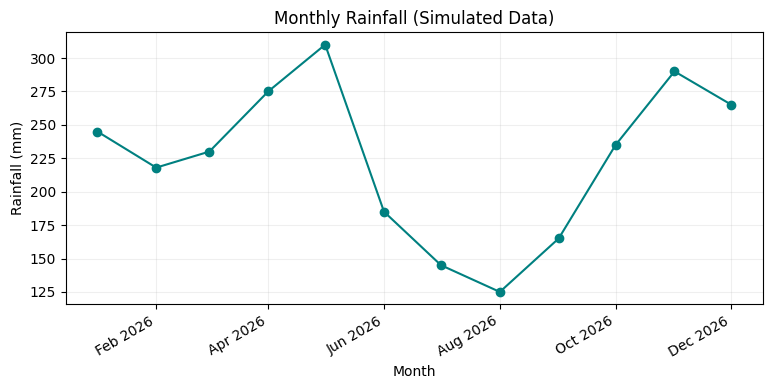

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

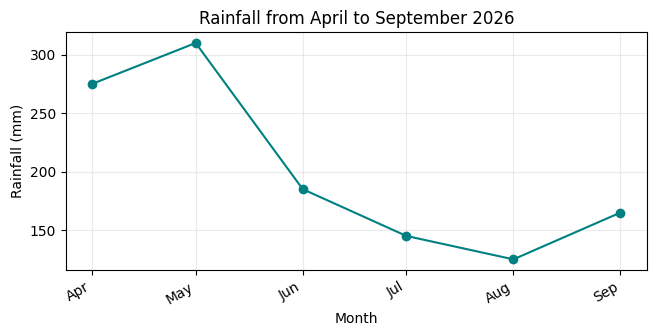

In [ ]:
selected_period = weather.loc["2026-04":"2026-09"]

fig, ax = plt.subplots(figsize=(7.5, 3.5))
# disini letak selected period nya
ax.plot(selected_period.index, selected_period["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Rainfall from April to September 2026", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)

fig.autofmt_xdate()
plt.show()

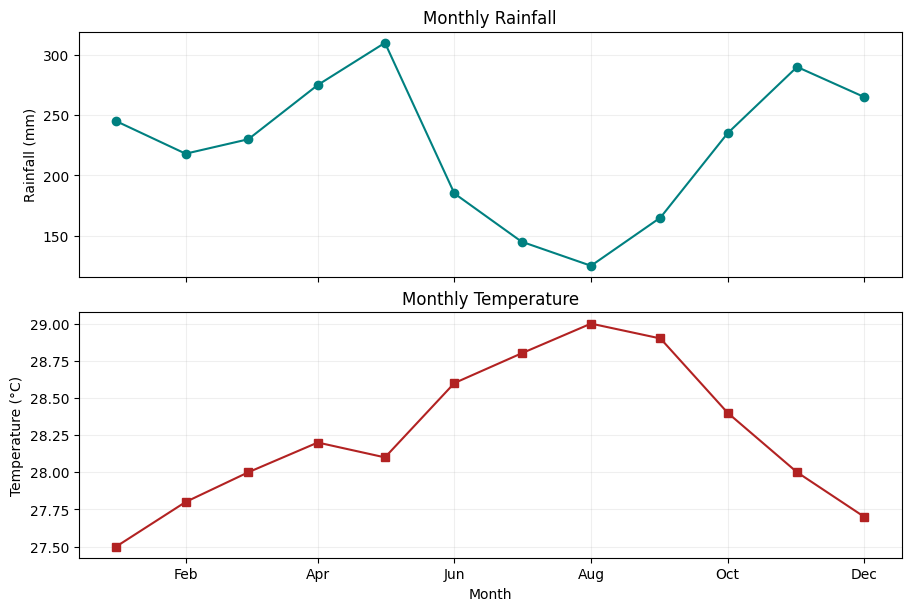

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
axes[0].plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
axes[0].set(title="Monthly Rainfall", ylabel="Rainfall (mm)")

axes[1].plot(weather.index, weather["Temperature_C"], marker="s", color="firebrick")
axes[1].set(title="Monthly Temperature", xlabel="Month", ylabel="Temperature (°C)")

axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

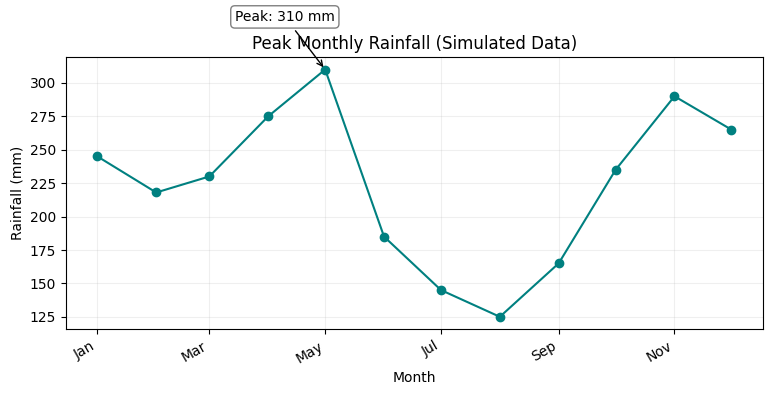

In [ ]:
peak_date = weather["Rainfall_mm"].idxmax()
peak_value = weather["Rainfall_mm"].max()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.annotate(f"Peak: {peak_value} mm",
            xy=(peak_date, peak_value), xytext=(-65, 35),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": "black"},
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "gray"})
ax.set(title="Peak Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()


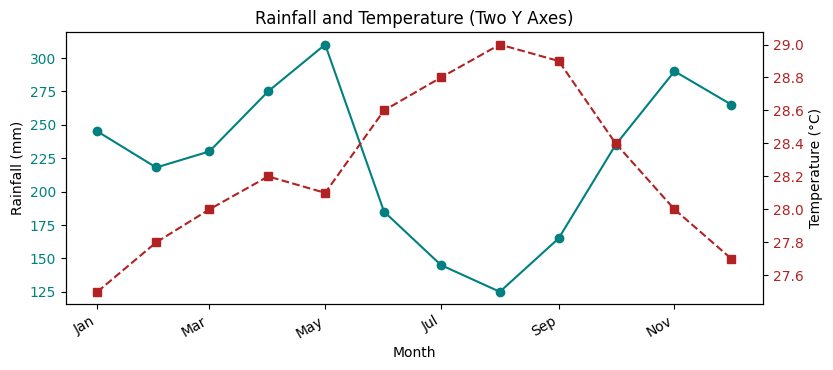

In [ ]:
fig, ax1 = plt.subplots(figsize=(9, 4))

ax2 = ax1.twinx()

ax1.plot(weather.index, weather["Rainfall_mm"], color="teal", marker="o", label="Rainfall")
ax2.plot(weather.index, weather["Temperature_C"], color="firebrick", marker="s", linestyle="--", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Month", ylabel="Rainfall (mm)")
ax2.set_ylabel("Temperature (°C)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()


In [ ]:
day = np.array([1,2,3,4,5,6])
temprature = np.array([25, 26, 28, 27, 29, 30])
rainfall = np.array([80, 110, 95, 125, 115, 140])
fig, ax1 = plt.subplots(figsize=(9, 4))

ax2 = ax1.twinx()

ax1.plot(weather.index, weather["Rainfall_mm"], color="teal", marker="o", label="Rainfall")
ax2.plot(weather.index, weather["Temperature_C"], color="firebrick", marker="s", linestyle="--", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Month", ylabel="Rainfall (mm)")
ax2.set_ylabel("Temperature (°C)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()


In [ ]:
rng = np.random.default_rng(12)
scores_a = np.clip(rng.normal(loc=78, scale=8, size=40), 0, 100)
scores_b = np.clip(rng.normal(loc=72, scale=10, size=40), 0, 100)
print("Class A: n =", len(scores_a), ", mean =", round(scores_a.mean(), 2))
print("Class B: n =", len(scores_b), ", mean =", round(scores_b.mean(), 2))

Class A: n = 40 , mean = 77.99
Class B: n = 40 , mean = 72.93


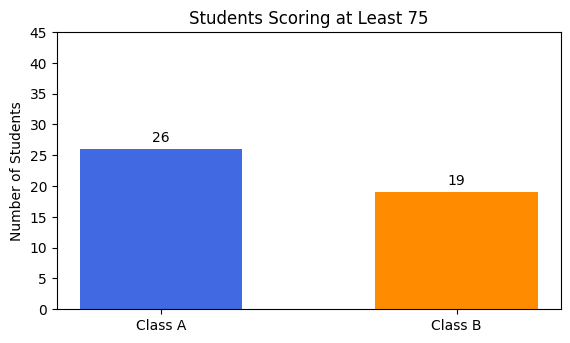

In [ ]:
categories = ["Class A", "Class B"]
pass_counts = np.array([(scores_a >= 75).sum(), (scores_b >= 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(categories, pass_counts, color=["royalblue", "darkorange"], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Students Scoring at Least 75", ylabel="Number of Students")
ax.set_ylim(0, len(scores_a) + 5)
plt.show()

In [ ]:
pass_counts

array([26, 19])

In [ ]:
team = np.array([]"A","B","C"])
completed = np.array([14, 18,12])
not_completed = np.array([6,4,8])

below_counts = np.array([(scores_a < 75).sum(), (scores_b < 75).sum(), (scores_c == 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.bar(categories, pass_counts, label="Score ≥ 75", color="seagreen")
ax.bar(categories, below_counts, bottom=pass_counts, label="Score < 75", color="lightcoral")
ax.set(title="Score Composition by Class", ylabel="Number of Students")

ax.legend()
plt.show()


NameError: name 'scores_c' is not defined

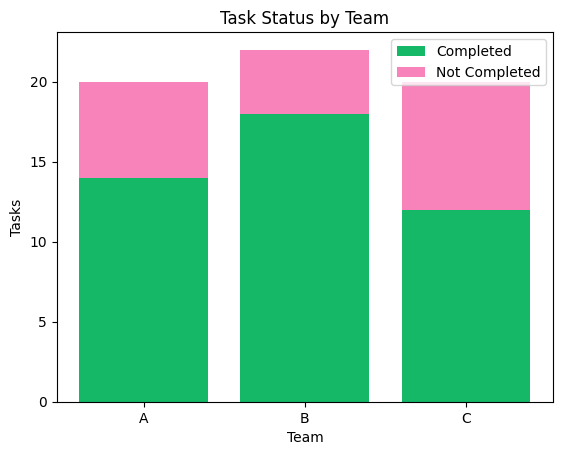

In [ ]:
team = np.array(["A", "B", "C"])
completed = np.array([14, 18, 12])
not_completed = np.array([6, 4, 8])

plt.bar(team, completed, label="Completed", color="#14b866")
plt.bar(team, not_completed, bottom=completed, label="Not Completed", color="#f783ba")
plt.title("Task Status by Team")
plt.xlabel("Team")
plt.ylabel("Tasks")
plt.legend()

plt.show()

In [ ]:
below_counts

array([14, 21])

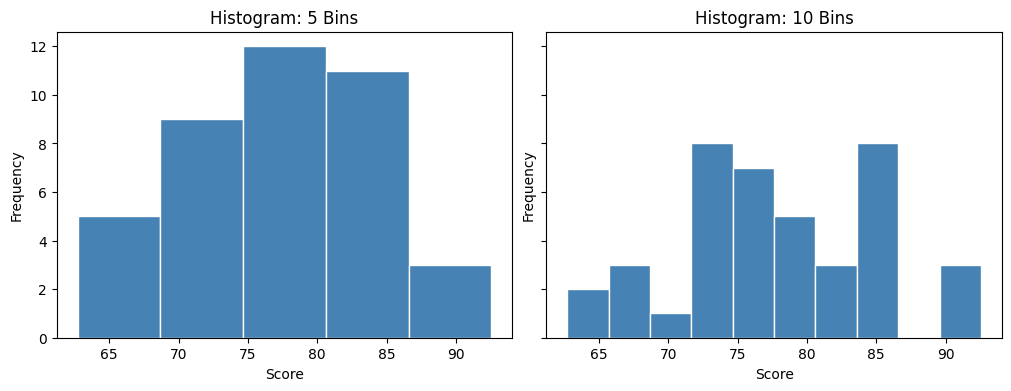

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [5, 10]):
    ax.hist(scores_a, bins=n_bins, color="steelblue", edgecolor="white")
    ax.set(title=f"Histogram: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()

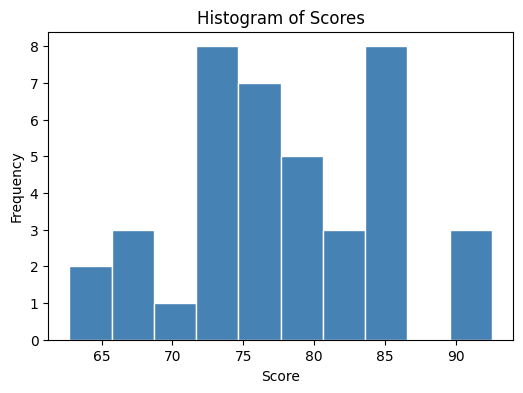

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(
    scores_a,
    bins=10,
    color="steelblue",
    edgecolor="white"
)
ax.set(
    title="Histogram of Scores",
    xlabel="Score",
    ylabel="Frequency"
)
plt.show()

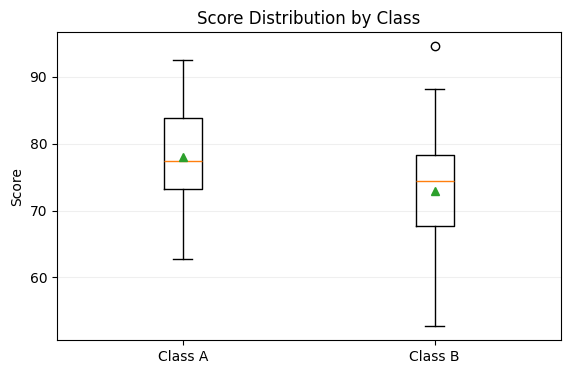

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4))
# segitiga adalah means jika showmeans true
ax.boxplot([scores_a, scores_b], showmeans=True)
ax.set_xticks([1, 2], categories)
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

[!] Memulai simulasi beban ekstrem pada 2 logical cores...


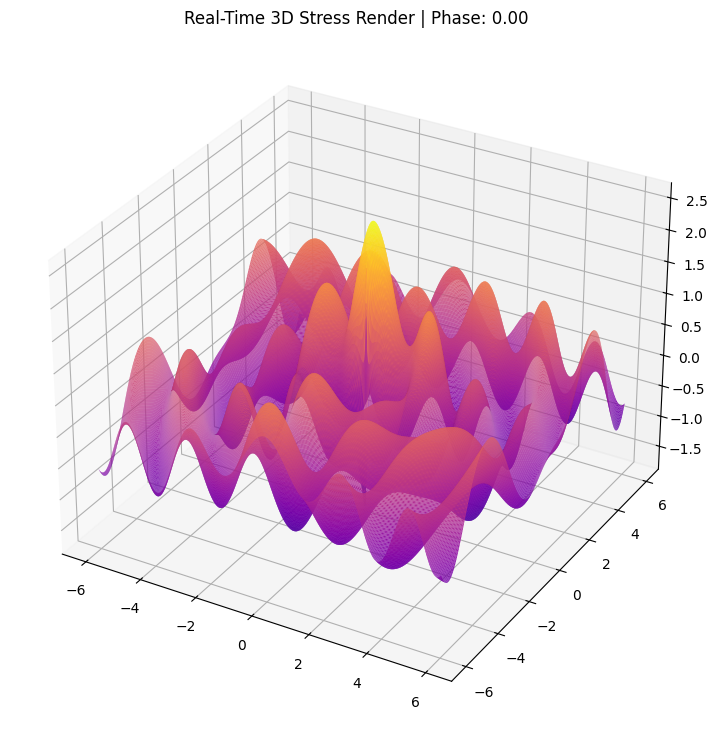

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

... (287 outputs left out)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
import os
import time
import math
import hashlib
import multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


class HeavyStressSimulator:
    def __init__(self, matrix_dim=750, tensor_dim=140, grid_res=1200, max_iter=150):
        self.matrix_dim = matrix_dim
        self.tensor_dim = tensor_dim
        self.grid_res = grid_res
        self.max_iter = max_iter
        self.cpu_cores = mp.cpu_count()

    def _compute_mandelbrot_fractal(self, x_min, x_max, y_min, y_max):
        """Menghitung himpunan fraktal Mandelbrot resolusi tinggi secara iteratif."""
        x = np.linspace(x_min, x_max, self.grid_res, dtype=np.float64)
        y = np.linspace(y_min, y_max, self.grid_res, dtype=np.float64)
        C = x[np.newaxis, :] + 1j * y[:, np.newaxis]
        Z = np.zeros_like(C)
        divergence_map = np.zeros(C.shape, dtype=np.int32)

        for i in range(self.max_iter):
            mask = np.abs(Z) <= 4.0
            Z[mask] = Z[mask] ** 2 + C[mask]
            divergence_map[mask] = i

        return np.log1p(divergence_map)

    def _tensor_and_spectral_decomposition(self, seed_offset):
        """Operasi aljabar linear berat: SVD, Eigenvalue, 3D FFT, dan Tensor Contraction."""
        rng = np.random.default_rng(seed=42 + seed_offset)

        # 1. Singular Value Decomposition (Kompleksitas O(n^3))
        mat_a = rng.standard_normal((self.matrix_dim, self.matrix_dim))
        u, s, vt = np.linalg.svd(mat_a, full_matrices=True)
        reconstructed = (u * s) @ vt

        # 2. Dekomposisi Eigenvalue pada matriks simetris
        sym_matrix = np.dot(reconstructed, reconstructed.T)
        eigenvalues = np.linalg.eigvalsh(sym_matrix)

        # 3. 3D Fast Fourier Transform & Kontraksi Tensor Einstein
        tensor_3d = rng.standard_normal((self.tensor_dim, self.tensor_dim, self.tensor_dim))
        freq_domain = np.fft.fftn(tensor_3d)
        contracted = np.einsum("ijk,ikl->ijl", np.abs(freq_domain), tensor_3d)

        return float(np.sum(eigenvalues) + np.mean(contracted))

    def _memory_and_crypto_churn(self, worker_id, cycles=15):
        """Membebani bandwidth RAM dan enkripsi SHA-512 berulang."""
        payload = os.urandom(1024 * 1024 * 32)  # Alokasi buffer 32 MB per worker
        digest = hashlib.sha512(payload).digest()

        for step in range(cycles):
            arr = np.frombuffer(payload, dtype=np.uint8).copy()
            arr = np.sort(arr[::-1])
            digest = hashlib.sha512(arr.tobytes() + digest).digest()
            payload = arr.tobytes()

        return f"Worker-{worker_id}: {digest.hex()[:16]}"

    def worker_routine(self, worker_id):
        """Pipeline penuh yang dijalankan secara paralel di setiap core CPU."""
        while True:
            _ = self._compute_mandelbrot_fractal(-2.0, 1.0, -1.5, 1.5)
            _ = self._tensor_and_spectral_decomposition(worker_id)
            _ = self._memory_and_crypto_churn(worker_id, cycles=5)

    def render_heavy_3d_surface(self):
        """Merender grafik 3D beresolusi ekstrem secara real-time untuk membebani GUI/GPU."""
        plt.ion()
        fig = plt.figure(figsize=(12, 9))
        ax = fig.add_subplot(111, projection="3d")

        axis_vals = np.linspace(-6, 6, 450)
        X, Y = np.meshgrid(axis_vals, axis_vals)

        phase = 0.0
        while True:
            ax.clear()
            R = np.sqrt(X**2 + Y**2) + 1e-8
            Z = (
                np.sin(R * 2.5 - phase) * np.cos(X * 1.5 + phase)
                + np.sin(Y * 2.0) / R
            )
            ax.plot_surface(
                X, Y, Z,
                cmap="plasma",
                edgecolor="none",
                rstride=1,
                cstride=1,
                antialiased=True
            )
            ax.set_title(f"Real-Time 3D Stress Render | Phase: {phase:.2f}")
            plt.draw()
            plt.pause(0.01)
            phase += 0.15

    def ignite(self):
        print(f"[!] Memulai simulasi beban ekstrem pada {self.cpu_cores} logical cores...")
        processes = []

        # Menjalankan worker paralel di seluruh core CPU
        for core_idx in range(self.cpu_cores):
            p = mp.Process(target=self.worker_routine, args=(core_idx,), daemon=True)
            p.start()
            processes.append(p)

        # Membebani thread utama dengan rendering 3D Matplotlib
        try:
            self.render_heavy_3d_surface()
        except KeyboardInterrupt:
            print("\n[!] Simulasi dihentikan oleh pengguna.")
            for p in processes:
                p.terminate()


if __name__ == "__main__":
    mp.freeze_support()
    # Naikkan angka parameter di bawah ini jika device masih terasa kuat
    simulator = HeavyStressSimulator(
        matrix_dim=900,
        tensor_dim=160,
        grid_res=1500,
        max_iter=200
    )
    simulator.ignite()

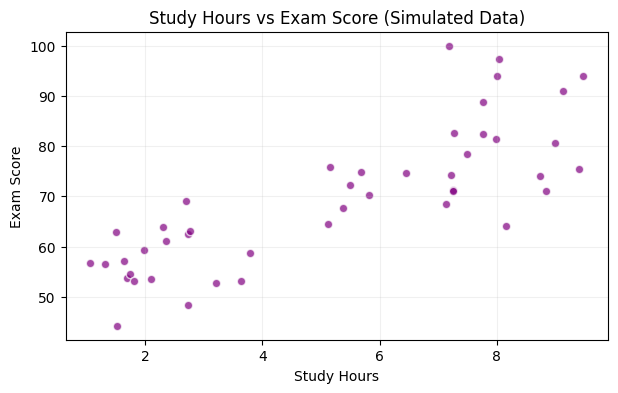

Pearson correlation: 0.81


In [ ]:
# buat data baru
study_hours = rng.uniform(1, 10, size=45)
exam_scores = np.clip(48 + 4.3 * study_hours + rng.normal(0, 9, size=45), 0, 100)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)

plt.show()
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))

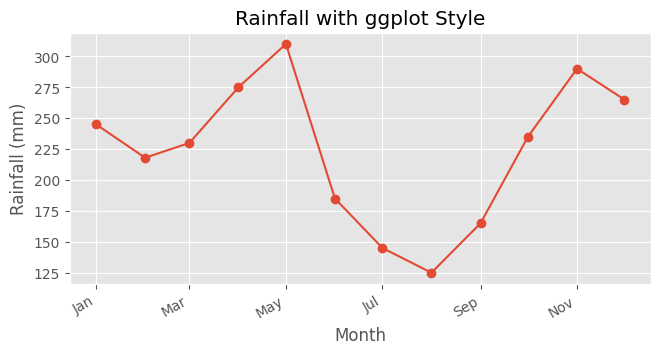

In [ ]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

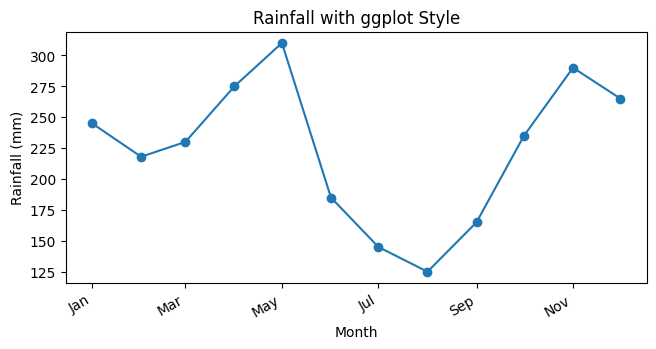

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()


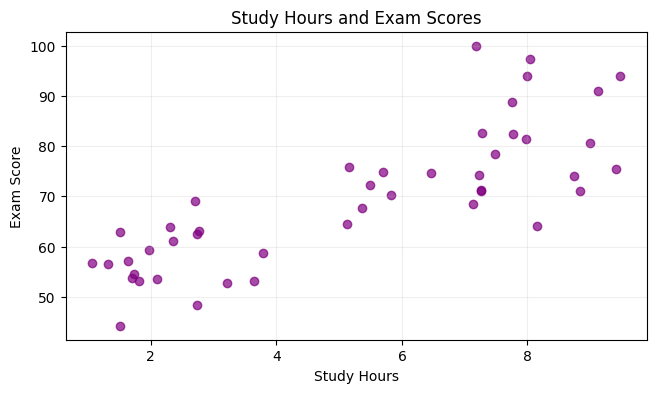

Saved to: /content/week12_figures


In [ ]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(study_hours, exam_scores, alpha=0.7, color="purple")
ax.set(title="Study Hours and Exam Scores", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "week12_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.pdf", bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.svg", bbox_inches="tight")
plt.show()
print("Saved to:", output_dir.resolve())

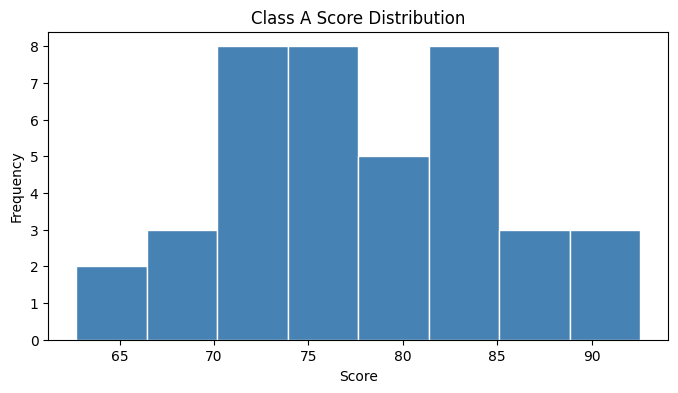

File: week12_figures/week12_histogram_300dpi.png
File size: 53.2 KB


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores_a, bins=8, edgecolor="white", color="steelblue")
ax.set(title="Class A Score Distribution", xlabel="Score", ylabel="Frequency")
file_path = output_dir / "week12_histogram_300dpi.png"
fig.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()
print("File:", file_path)
print("File size:", round(file_path.stat().st_size / 1024, 1), "KB")

In [ ]:
for name in ["week12_scatter.png", "week12_scatter.pdf", "week12_scatter.svg",
             "week12_histogram_300dpi.png"]:
    path = output_dir / name
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

week12_scatter.png: Found
week12_scatter.pdf: Found
week12_scatter.svg: Found
week12_histogram_300dpi.png: Found
